Original Trotter Benchmark Depth: 7


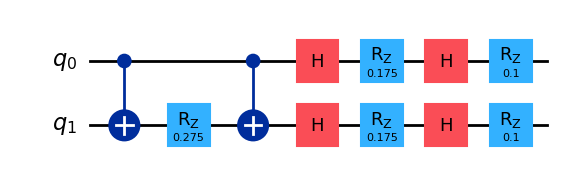

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, qasm2
from qiskit.synthesis import generate_basic_approximations
from qiskit.transpiler.passes import SolovayKitaev
from qiskit.transpiler import PassManager
# Building a 2-qubit Trotterized time-evolution step: exp(-i * H * dt)
# Hamiltonian terms: H = J_zz (Z0 Z1) + h_x (X0 + X1) + h_z (Z0 + Z1)
qc_trotter = QuantumCircuit(2, name="Trotter_Step")
dt = 0.25
j_zz, h_x, h_z = 0.55, 0.35, 0.20
# 1. ZZ interaction term: CNOT -> Rz(2 * J_zz * dt) -> CNOT
qc_trotter.cx(0, 1)
qc_trotter.rz(2 * j_zz * dt, 1)
qc_trotter.cx(0, 1)
# 2. Local transverse X terms: H -> Rz(2 * h_x * dt) -> H
for q in range(2):
 qc_trotter.h(q)
 qc_trotter.rz(2 * h_x * dt, q)
 qc_trotter.h(q)
# 3. Local Z terms: Rz(2 * h_z * dt)
for q in range(2):
 qc_trotter.rz(2 * h_z * dt, q)
print(f"Original Trotter Benchmark Depth: {qc_trotter.depth()}")
qc_trotter.draw(output='mpl')

C:\Users\USER\AppData\Local\Temp\ipykernel_9576\669176852.py:3: DeprecationWarning: The function ``qiskit.synthesis.discrete_basis.generate_basis_approximations.generate_basic_approximations()`` is deprecated as of Qiskit 2.3. It will be removed no earlier than 3 months after the release date. Use the SolovayKitaevDecomposition class directly, to generate, store, and load the basic approximations.
  approx_table = generate_basic_approximations(basis_gates, depth=3)


FTQC Compiled Trotter Circuit Depth: 44


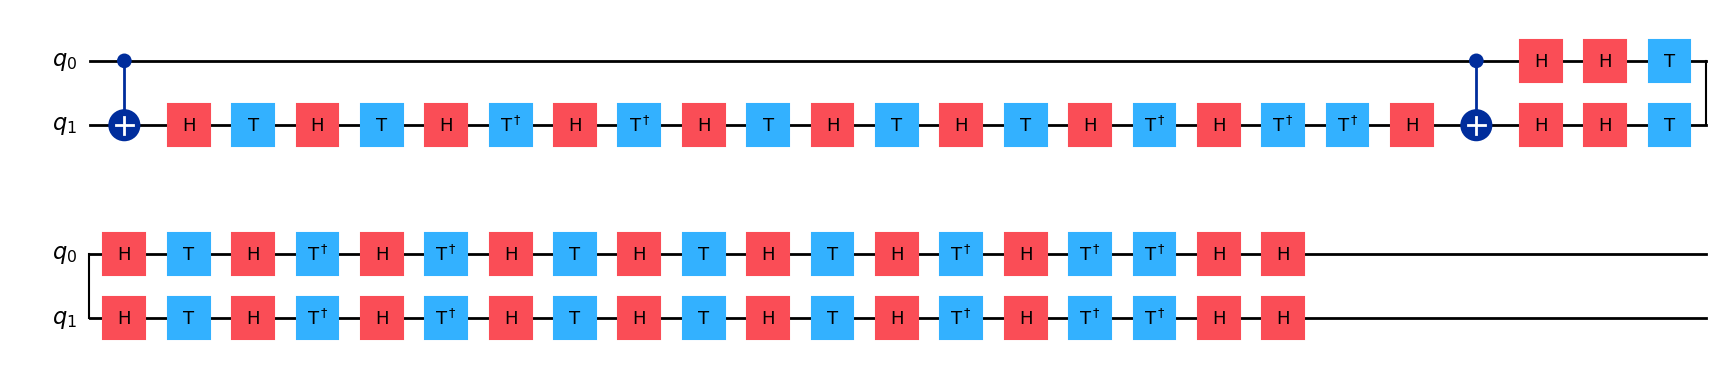

In [7]:
# Generating basis sequences and run Solovay-Kitaev compilation across all rotation gates
basis_gates = ['h', 's', 't', 'tdg']
approx_table = generate_basic_approximations(basis_gates, depth=3)
sk_pass = SolovayKitaev(recursion_degree=2, basic_approximations=approx_table)
pm = PassManager([sk_pass])
# Compiling all continuous rotations in the Trotter circuit to Clifford+T
qc_trotter_ftqc = pm.run(qc_trotter)
print(f"FTQC Compiled Trotter Circuit Depth: {qc_trotter_ftqc.depth()}")
qc_trotter_ftqc.draw(output='mpl')

In [8]:
gate_counts = qc_trotter_ftqc.count_ops()
t_count = gate_counts.get('t', 0) + gate_counts.get('tdg', 0)
cx_count = gate_counts.get('cx', 0)
clifford_count = gate_counts.get('h', 0) + gate_counts.get('s', 0) + cx_count
print("="*45)
print("DAY 3 TROTTER BENCHMARK FTQC PROFILE")
print("="*45)
print(f"Logical Qubits : {qc_trotter_ftqc.num_qubits}")
print(f"Total Gate Count : {sum(gate_counts.values())}")
print(f"Baseline T-Count (T+Tdg): {t_count}")
print(f"Clifford Operations : {clifford_count} (CX: {cx_count})")
print(f"Circuit Depth : {qc_trotter_ftqc.depth()}")
print("Gate Breakdown :", dict(gate_counts))
print("="*45)

DAY 3 TROTTER BENCHMARK FTQC PROFILE
Logical Qubits : 2
Total Gate Count : 66
Baseline T-Count (T+Tdg): 30
Clifford Operations : 36 (CX: 2)
Circuit Depth : 44
Gate Breakdown : {'h': 34, 't': 15, 'tdg': 15, 'cx': 2}


In [9]:
# Exporting to standard OpenQASM format for graph-theoretic ZX reduction in Week 2
try:
 qasm_str = qasm2.dumps(qc_trotter_ftqc)
except Exception:
 qasm_str = qc_trotter_ftqc.qasm()
with open("trotter_benchmark_ftqc.qasm", "w") as f:
 f.write(qasm_str)
print("Saved 'trotter_benchmark_ftqc.qasm' successfully for Day 4 / PyZX pipeline.")

Saved 'trotter_benchmark_ftqc.qasm' successfully for Day 4 / PyZX pipeline.


In [11]:
!git add Day_3_Chemistry_Benchmark.ipynb trotter_benchmark_ftqc.qasm
!git commit -m "Day 3: Built Trotterized chemistry benchmark, Clifford+T synthesis, and QASM export"

[master ea23792] Day 3: Built Trotterized chemistry benchmark, Clifford+T synthesis, and QASM export
 1 file changed, 126 insertions(+), 56 deletions(-)
